# Seoul Bike Sharing Demand: Exploratory Data Analysis

**Project:** Task 03 – Real-World Dataset Analysis  
**Dataset:** Seoul Bike Sharing Demand (hourly observations)  
**Period:** 1 December 2017 – 30 November 2018  
**Objective:** Understand how time, season and weather relate to hourly bike-rental demand and translate the patterns into operational recommendations.

This notebook is designed to run from the project folder. It loads the original CSV from `data/` and writes reproducible outputs to `results/`.

## 1. Business understanding and analytical questions

A bike-sharing operator needs to anticipate when demand is likely to rise or fall so that bicycles, docks and maintenance resources can be planned. This analysis addresses:

1. What does the dataset contain, and is it suitable for hourly demand analysis?
2. How is rental demand distributed, and are there unusual observations?
3. How does demand vary by hour, season, weekday/weekend and functioning-day status?
4. How are weather variables associated with rentals?
5. What operational actions are suggested by the observed patterns?

The analysis is descriptive and correlational. It does not establish causal effects or provide a validated forecasting model.

## 2. Imports and reproducible project paths

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebook lives in notebooks/; project root is its parent.
PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif not (PROJECT_DIR / "data" / "SeoulBikeData.csv").exists():
    PROJECT_DIR = Path.cwd() / "Task-03-Real-World-Dataset-Analysis"
DATA_PATH = PROJECT_DIR / "data" / "SeoulBikeData.csv"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT_DIR)
print("Dataset exists:", DATA_PATH.exists())

Project directory: /mnt/data/Task3_Resubmission_Package
Dataset exists: True


## 3. Load data and inspect structure

The source file is read with `cp1252` encoding. The original dataset is retained unchanged; transformations are performed on a working copy.

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="cp1252")
df = raw.copy()
print("Shape:", df.shape)
display(df.head())
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values, "non_null": df.notna().sum().values}))

Shape: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


,column,dtype,non_null
0,Date,object,8760
1,Rented Bike Count,int64,8760
2,Hour,int64,8760
3,Temperature(°C),float64,8760
4,Humidity(%),int64,8760
5,Wind speed (m/s),float64,8760
6,Visibility (10m),int64,8760
7,Dew point temperature(°C),float64,8760
8,Solar Radiation (MJ/m2),float64,8760
9,Rainfall(mm),float64,8760


### Column guide

- `Date`, `Hour`: observation date and hour (0–23).
- `Rented Bike Count`: hourly rental count; primary outcome variable.
- Temperature, humidity, wind speed, visibility, dew point, solar radiation, rainfall and snowfall: weather measurements.
- `Seasons`, `Holiday`, `Functioning Day`: categorical context fields.

The source contains 14 columns and hourly records.

## 4. Data quality assessment

Check missing values, exact duplicates, uniqueness of date-hour keys, valid hour range, plausible weather ranges and expected category values. Statistical outliers are assessed separately from data errors.

In [3]:
quality_checks = {
    "rows": len(df),
    "columns": len(df.columns),
    "missing_cells": int(df.isna().sum().sum()),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "duplicate_date_hour_keys": int(df.duplicated(["Date", "Hour"]).sum()),
}
display(pd.Series(quality_checks, name="value"))
display(df.isna().sum().rename("missing_values").to_frame())

rows                        8760
columns                       14
missing_cells                  0
exact_duplicate_rows           0
duplicate_date_hour_keys       0
Name: value, dtype: int64

,missing_values
Date,0
Rented Bike Count,0
Hour,0
Temperature(°C),0
Humidity(%),0
Wind speed (m/s),0
Visibility (10m),0
Dew point temperature(°C),0
Solar Radiation (MJ/m2),0
Rainfall(mm),0


## 5. Data cleaning and preprocessing

Standardize column names, parse dates using day/month/year format, convert numeric fields explicitly and trim categorical text. No observations are removed unless a documented quality issue requires it. The source has no missing values or duplicates, so no imputation or duplicate removal is necessary.

In [4]:
df.columns = [c.strip().replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_").replace("°C", "C").replace("%", "pct") for c in df.columns]
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y", errors="coerce")
numeric_cols = ["Rented_Bike_Count", "Hour", "TemperatureC", "Humiditypct", "Wind_speed_m_s", "Visibility_10m", "Dew_point_temperatureC", "Solar_Radiation_MJ_m2", "Rainfallmm", "Snowfall_cm"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in ["Seasons", "Holiday", "Functioning_Day"]:
    df[col] = df[col].astype("string").str.strip()
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Weekday"] = df["Date"].dt.day_name()
df["Day_Type"] = np.where(df["Weekday"].isin(["Saturday", "Sunday"]), "Weekend", "Weekday")
print("Processed shape:", df.shape)
print("Remaining missing cells:", int(df.isna().sum().sum()))
display(df.head())

Processed shape: (8760, 18)
Remaining missing cells: 0


,Date,Rented_Bike_Count,Hour,TemperatureC,Humiditypct,Wind_speed_m_s,Visibility_10m,Dew_point_temperatureC,Solar_Radiation_MJ_m2,Rainfallmm,Snowfall_cm,Seasons,Holiday,Functioning_Day,Month,Month_Name,Weekday,Day_Type
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,December,Friday,Weekday
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,December,Friday,Weekday
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,12,December,Friday,Weekday
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,December,Friday,Weekday
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,December,Friday,Weekday


## 6. Domain validation and outlier assessment

IQR fences identify statistically unusual rental counts, not necessarily incorrect records. High demand may be genuine during commuting or event periods. Therefore, flagged rows are retained and interpreted rather than automatically deleted.

In [5]:
q1, q3 = df["Rented_Bike_Count"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (df["Rented_Bike_Count"] < lower_fence) | (df["Rented_Bike_Count"] > upper_fence)
validation = pd.Series({
    "invalid_dates": int(df["Date"].isna().sum()),
    "negative_rentals": int((df["Rented_Bike_Count"] < 0).sum()),
    "hour_out_of_range": int((~df["Hour"].between(0, 23)).sum()),
    "humidity_out_of_range": int((~df["Humiditypct"].between(0, 100)).sum()),
    "negative_wind_speed": int((df["Wind_speed_m_s"] < 0).sum()),
    "negative_rainfall": int((df["Rainfallmm"] < 0).sum()),
    "negative_snowfall": int((df["Snowfall_cm"] < 0).sum()),
    "unexpected_season": int((~df["Seasons"].isin(["Spring", "Summer", "Autumn", "Winter"])).sum()),
    "unexpected_holiday": int((~df["Holiday"].isin(["Holiday", "No Holiday"])).sum()),
    "unexpected_functioning_day": int((~df["Functioning_Day"].isin(["Yes", "No"])).sum()),
    "IQR_outlier_flags": int(outlier_mask.sum()),
})
display(validation)
print(f"IQR fences: {lower_fence:.2f} to {upper_fence:.2f}")

invalid_dates                   0
negative_rentals                0
hour_out_of_range               0
humidity_out_of_range           0
negative_wind_speed             0
negative_rainfall               0
negative_snowfall               0
unexpected_season               0
unexpected_holiday              0
unexpected_functioning_day      0
IQR_outlier_flags             158
dtype: int64

IQR fences: -1120.38 to 2376.62


## 7. Descriptive statistics and rental distribution

Compare mean and median to understand skew, and use quartiles and standard deviation to describe variability. A right-skewed distribution is common in hourly demand data because a small number of peak hours can have much higher counts.

,count,mean,std,min,25%,50%,75%,max
Rented_Bike_Count,8760.0,704.60,645.00,0.0,191.00,504.50,1065.25,3556.00
Hour,8760.0,11.50,6.92,0.0,5.75,11.50,17.25,23.00
TemperatureC,8760.0,12.88,11.94,-17.8,3.50,13.70,22.50,39.40
Humiditypct,8760.0,58.23,20.36,0.0,42.00,57.00,74.00,98.00
Wind_speed_m_s,8760.0,1.72,1.04,0.0,0.90,1.50,2.30,7.40
Visibility_10m,8760.0,1436.83,608.30,27.0,940.00,1698.00,2000.00,2000.00
Dew_point_temperatureC,8760.0,4.07,13.06,-30.6,-4.70,5.10,14.80,27.20
Solar_Radiation_MJ_m2,8760.0,0.57,0.87,0.0,0.00,0.01,0.93,3.52
Rainfallmm,8760.0,0.15,1.13,0.0,0.00,0.00,0.00,35.00
Snowfall_cm,8760.0,0.08,0.44,0.0,0.00,0.00,0.00,8.80


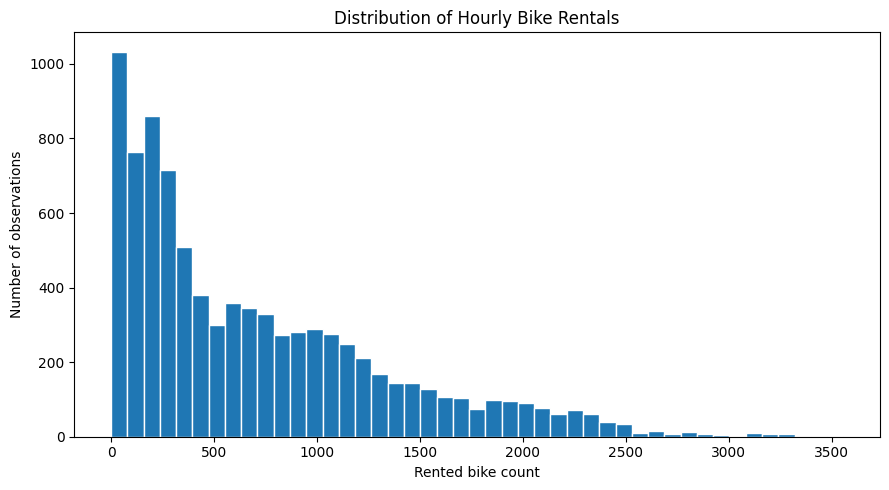

Mean: 704.6 | Median: 504.5


In [6]:
display(df[numeric_cols].describe().T.round(2))
plt.figure(figsize=(9, 5))
plt.hist(df["Rented_Bike_Count"], bins=45, edgecolor="white")
plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Rented bike count")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()
print("Mean:", round(df["Rented_Bike_Count"].mean(), 2), "| Median:", round(df["Rented_Bike_Count"].median(), 2))

## 8. Overall demand KPIs

The following metrics summarize the observed year. The maximum is a single hourly observation and should not be confused with the average peak-hour profile.

In [7]:
kpis = pd.Series({
    "records": len(df),
    "total_rentals": int(df["Rented_Bike_Count"].sum()),
    "average_hourly_rentals": round(df["Rented_Bike_Count"].mean(), 2),
    "median_hourly_rentals": round(df["Rented_Bike_Count"].median(), 2),
    "maximum_hourly_rentals": int(df["Rented_Bike_Count"].max()),
    "maximum_date": str(df.loc[df["Rented_Bike_Count"].idxmax(), "Date"].date()),
    "maximum_hour": int(df.loc[df["Rented_Bike_Count"].idxmax(), "Hour"]),
})
display(kpis.to_frame("value"))

,value
records,8760
total_rentals,6172314
average_hourly_rentals,704.6
median_hourly_rentals,504.5
maximum_hourly_rentals,3556
maximum_date,2018-06-19
maximum_hour,18


## 9. Hour-of-day demand analysis

Average demand by hour reveals the typical intraday profile. Compare the highest and lowest average hours and consider how staffing, rebalancing and bicycle availability could respond.

,Hour,mean,median,sum,count
0,0,541.46,513.0,197633,365
1,1,426.18,401.0,155557,365
2,2,301.63,265.0,110095,365
3,3,203.33,176.0,74216,365
4,4,132.59,119.0,48396,365
5,5,139.08,129.0,50765,365
6,6,287.56,232.0,104961,365
7,7,606.01,426.0,221192,365
8,8,1015.70,728.0,370731,365
9,9,645.98,680.0,235784,365


Highest average hour: 18:00 (1502.93)
Lowest average hour: 04:00 (132.59)


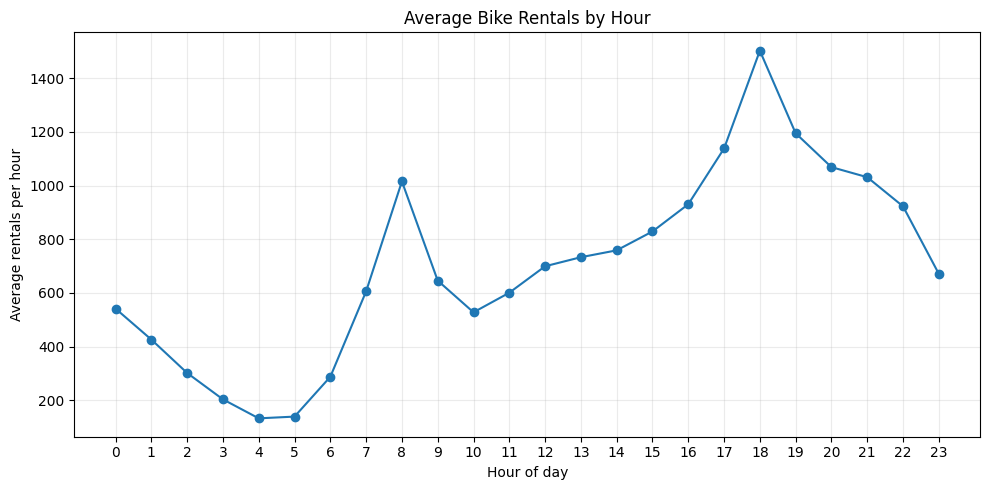

In [8]:
hourly = df.groupby("Hour")["Rented_Bike_Count"].agg(["mean", "median", "sum", "count"]).reset_index()
display(hourly.round(2))
peak = hourly.loc[hourly["mean"].idxmax()]
low = hourly.loc[hourly["mean"].idxmin()]
print(f"Highest average hour: {int(peak.Hour):02d}:00 ({peak['mean']:.2f})")
print(f"Lowest average hour: {int(low.Hour):02d}:00 ({low['mean']:.2f})")
plt.figure(figsize=(10, 5)); plt.plot(hourly.Hour, hourly["mean"], marker="o")
plt.xticks(range(24)); plt.grid(alpha=.25); plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day"); plt.ylabel("Average rentals per hour"); plt.tight_layout(); plt.show()

## 10. Seasonal demand analysis

Compare mean, median and total rentals by season. Mean demand is more suitable for comparing typical hourly demand because seasonal observation counts are not exactly identical.

,Seasons,mean,median,sum,count
0,Summer,1034.07,905.5,2283234,2208
1,Autumn,819.60,763.5,1790002,2184
2,Spring,730.03,583.0,1611909,2208
3,Winter,225.54,203.0,487169,2160


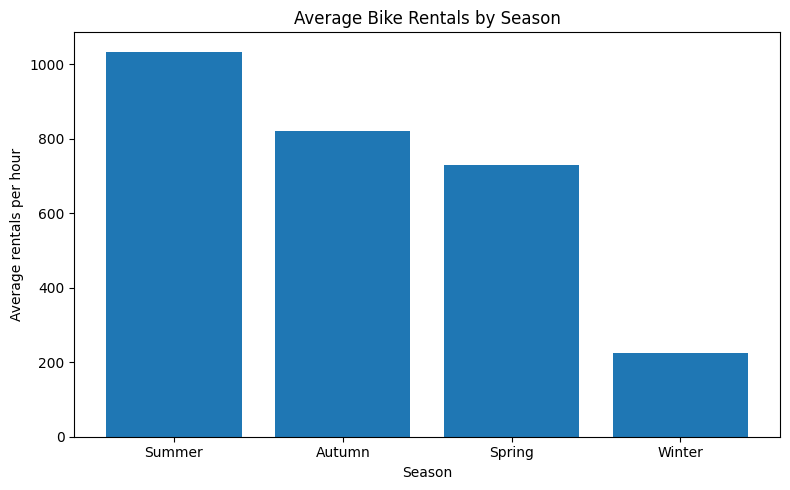

<Figure size 800x500 with 0 Axes>

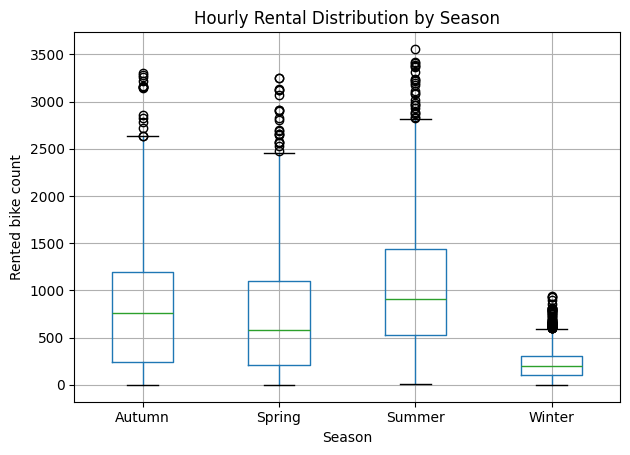

In [9]:
seasonal = df.groupby("Seasons")["Rented_Bike_Count"].agg(["mean", "median", "sum", "count"]).sort_values("mean", ascending=False).reset_index()
display(seasonal.round(2))
plt.figure(figsize=(8, 5)); plt.bar(seasonal.Seasons, seasonal["mean"])
plt.title("Average Bike Rentals by Season"); plt.xlabel("Season"); plt.ylabel("Average rentals per hour"); plt.tight_layout(); plt.show()
plt.figure(figsize=(8, 5)); df.boxplot(column="Rented_Bike_Count", by="Seasons")
plt.suptitle(""); plt.title("Hourly Rental Distribution by Season"); plt.xlabel("Season"); plt.ylabel("Rented bike count"); plt.tight_layout(); plt.show()

## 11. Weekday, weekend and functioning-day comparison

Day type is derived from the date. Compare means and medians rather than relying only on totals, because groups contain different numbers of hourly observations. Functioning-day status is a separate operational variable.

In [10]:
day_summary = df.groupby("Day_Type")["Rented_Bike_Count"].agg(["mean", "median", "sum", "count"]).reset_index()
function_summary = df.groupby("Functioning_Day")["Rented_Bike_Count"].agg(["mean", "median", "sum", "count"]).reset_index()
display(day_summary.round(2)); display(function_summary.round(2))

,Day_Type,mean,median,sum,count
0,Weekday,719.45,527.0,4506628,6264
1,Weekend,667.34,463.0,1665686,2496


,Functioning_Day,mean,median,sum,count
0,No,0.00,0.0,0,295
1,Yes,729.16,542.0,6172314,8465


## 12. Weather relationships and correlation

Pearson correlation measures linear association. It does not control for time, seasonality or other confounders and does not imply that changing a weather variable would cause the observed rental change.

,Pearson correlation with rentals
TemperatureC,0.539
Hour,0.410
Dew_point_temperatureC,0.380
Solar_Radiation_MJ_m2,0.262
Visibility_10m,0.199
Month,0.134
Wind_speed_m_s,0.121
Rainfallmm,-0.123
Snowfall_cm,-0.142
Humiditypct,-0.200


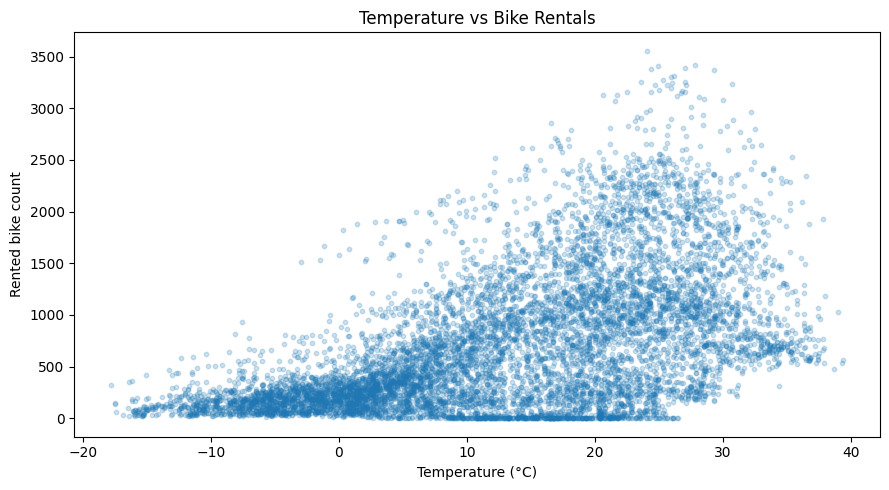

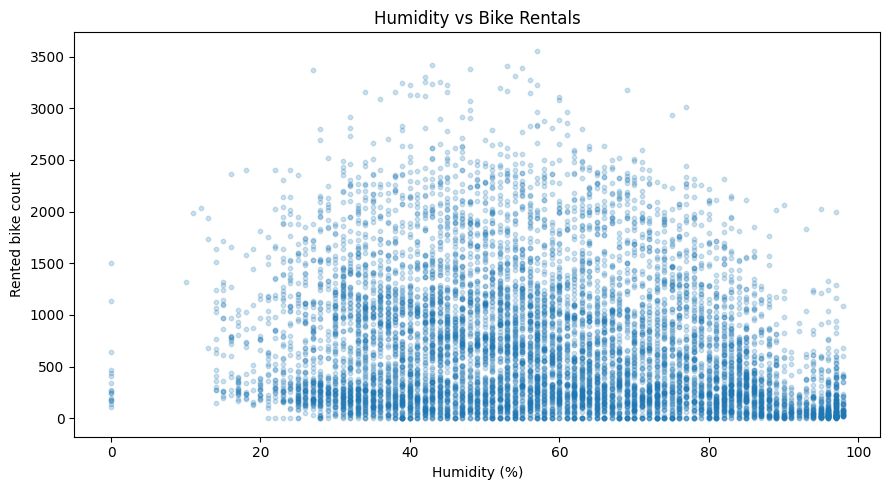

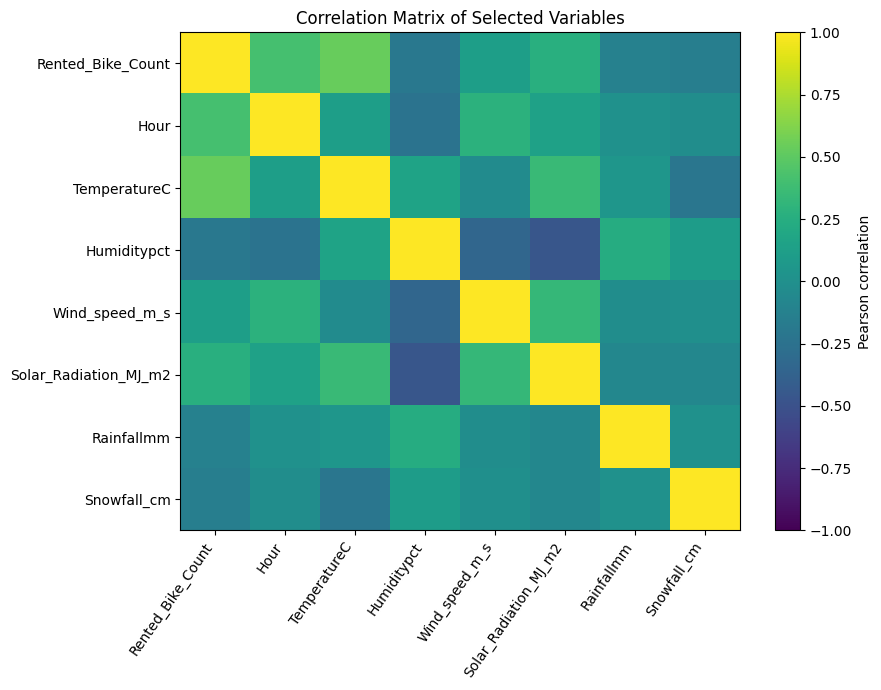

In [11]:
corr = df.select_dtypes(include="number").corr(numeric_only=True)["Rented_Bike_Count"].drop("Rented_Bike_Count").sort_values(ascending=False)
display(corr.to_frame("Pearson correlation with rentals").round(3))
plt.figure(figsize=(9, 5)); plt.scatter(df["TemperatureC"], df["Rented_Bike_Count"], alpha=.22, s=10)
plt.title("Temperature vs Bike Rentals"); plt.xlabel("Temperature (°C)"); plt.ylabel("Rented bike count"); plt.tight_layout(); plt.show()
plt.figure(figsize=(9, 5)); plt.scatter(df["Humiditypct"], df["Rented_Bike_Count"], alpha=.22, s=10)
plt.title("Humidity vs Bike Rentals"); plt.xlabel("Humidity (%)"); plt.ylabel("Rented bike count"); plt.tight_layout(); plt.show()
features = ["Rented_Bike_Count", "Hour", "TemperatureC", "Humiditypct", "Wind_speed_m_s", "Solar_Radiation_MJ_m2", "Rainfallmm", "Snowfall_cm"]
cm = df[features].corr()
plt.figure(figsize=(9, 7)); plt.imshow(cm, vmin=-1, vmax=1, aspect="auto"); plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(features)), features, rotation=55, ha="right"); plt.yticks(range(len(features)), features)
plt.title("Correlation Matrix of Selected Variables"); plt.tight_layout(); plt.show()

## 13. Findings and business interpretation

Use the computed summaries to distinguish descriptive findings from hypotheses. Seasonal and hourly patterns can inform resource planning, while weather correlations can support demand monitoring. The analysis does not identify causal effects or prove why a pattern occurs.

In [12]:
summer_avg = seasonal.loc[seasonal.Seasons == "Summer", "mean"].iloc[0]
winter_avg = seasonal.loc[seasonal.Seasons == "Winter", "mean"].iloc[0]
weekday_avg = day_summary.loc[day_summary.Day_Type == "Weekday", "mean"].iloc[0]
weekend_avg = day_summary.loc[day_summary.Day_Type == "Weekend", "mean"].iloc[0]
print(f"Summer average is {summer_avg / winter_avg:.2f} times the winter average.")
print(f"Weekday average is {(weekday_avg / weekend_avg - 1) * 100:.1f}% higher than weekend average.")
print(f"Temperature correlation: {corr.get('TemperatureC', np.nan):.3f}")
print(f"Humidity correlation: {corr.get('Humiditypct', np.nan):.3f}")

Summer average is 4.58 times the winter average.
Weekday average is 7.8% higher than weekend average.
Temperature correlation: 0.539
Humidity correlation: -0.200


## 14. Business recommendations

1. **Peak-hour readiness:** Use the morning and evening demand profile to plan bicycle availability, station checks and rebalancing. Validate local station-level demand before allocating resources.
2. **Seasonal planning:** Prepare higher capacity and maintenance coverage for warmer seasons, while reviewing winter operating costs and demand patterns.
3. **Weather-aware monitoring:** Include temperature, humidity and precipitation in operational dashboards, but validate their incremental predictive value before using them for automated decisions.
4. **Outlier review:** Investigate flagged high-demand hours against events, service disruptions and operational records rather than deleting them as errors.
5. **Further segmentation:** Analyse demand by station, neighbourhood, holiday and hour if those fields become available; aggregate city-level patterns may hide local differences.

## 15. Limitations and conclusion

The dataset covers one year of hourly observations. It does not provide station-level location, customer type, trip duration or event information in the fields analysed here. Aggregated relationships may hide local differences, and a single year may not represent future conditions. Correlation is not causation. A forecasting project would require a time-based train/test split, suitable baselines, error metrics and validation across seasonal periods.

Overall, the data shows substantial hourly and seasonal variation, a higher average on weekdays than weekends, and a moderate positive association between temperature and rentals. These findings can guide further operational analysis, but should be validated with station-level and multi-year data before major decisions.

## 16. Reproducibility and output files

The analysis saves a cleaned dataset, quality report, KPI and grouped summary CSVs, and charts in `results/`. The original CSV in `data/` remains unchanged.